# 03 · Modelo 1: Regresión lineal regularizada (Ridge / Lasso)

**Proyecto 3 · Minería de Datos (ISW-911) · Grupo Innova S.A.**  
**Responsable:** Jose Fabio Oconitrillo  
**Rama de trabajo:** `feature/fabio-modelo-lineal`  
**Criterio de la rúbrica:** 2. Modelado y Entrenamiento (30 %)

> Línea base lineal + Ridge y Lasso con ajuste de `alpha` por validación cruzada (5 folds).

_Regla: no borrar celdas de otros, documentar CADA decisión en Markdown (qué se hizo, por qué y qué alternativa se descartó)._

In [1]:
import sys
sys.path.append("..")  # para importar src/ desde notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.datos import cargar_datos, dividir_train_test

sns.set_theme(style="whitegrid")
df = cargar_datos()
X_train, X_test, y_train, y_test = dividir_train_test(df)
print("Datos:", df.shape, "| Train:", X_train.shape, "| Test:", X_test.shape)

Datos: (110196, 27) | Train: (88156, 11) | Test: (22040, 11)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV, cross_val_score

from src.preprocesamiento import crear_preprocesador_lineal
from src.evaluacion import calcular_metricas, registrar_metricas

ALPHAS = np.logspace(-3, 3, 13)   # 0.001 ... 1000, 13 valores en escala logarítmica

**Qué se evalúa y cómo:**
- Todos los modelos son un `Pipeline([("prep", crear_preprocesador_lineal()), ("modelo", ...)])`, así el escalado y el One-Hot se ajustan **solo con Train** y se reajustan dentro de cada fold de la validación cruzada (ver notebook 02, sección 4).
- Los hiperparámetros se eligen con **validación cruzada de 5 folds sobre Train** (`config.CV_FOLDS`), con `scoring="neg_root_mean_squared_error"` (RMSE; scikit-learn lo devuelve negativo porque siempre maximiza). **El Test no se usa para elegir nada**: solo se mira al final para reportar.
- Métricas obligatorias: RMSE, MAE y R² sobre Test (`src/evaluacion.py`).

## 1. Línea base: LinearRegression

Antes de regularizar, dos referencias:
- **Cotizar siempre con la mediana** (`DummyRegressor`): el error que tendría Grupo Innova sin ningún modelo. Cualquier modelo útil tiene que superarla.
- **Regresión lineal sin regularizar** (mínimos cuadrados): el punto de partida del Modelo 1. Ridge y Lasso solo se justifican si mejoran sobre ella.

In [3]:
mediana = Pipeline([("prep", crear_preprocesador_lineal()), ("modelo", DummyRegressor(strategy="median"))])
mediana.fit(X_train, y_train)
print("Cotizar con la mediana (Test):", {k: round(v, 3) for k, v in calcular_metricas(y_test, mediana.predict(X_test)).items()})

lineal = Pipeline([("prep", crear_preprocesador_lineal()), ("modelo", LinearRegression())])
lineal.fit(X_train, y_train)

rmse_cv_lineal = -cross_val_score(lineal, X_train, y_train, cv=config.CV_FOLDS,
                                  scoring="neg_root_mean_squared_error", n_jobs=-1)
print(f"LinearRegression · RMSE CV (5 folds): {rmse_cv_lineal.mean():.3f} ± {rmse_cv_lineal.std():.3f}")
print("LinearRegression (Test):", {k: round(v, 3) for k, v in calcular_metricas(y_test, lineal.predict(X_test)).items()})

Cotizar con la mediana (Test): {'RMSE': 16.141, 'MAE': 7.698, 'R2': -0.051}
LinearRegression · RMSE CV (5 folds): 9.865 ± 0.258
LinearRegression (Test): {'RMSE': 9.602, 'MAE': 5.005, 'R2': 0.628}


**Lectura:** la regresión lineal explica alrededor del **63 % de la variación del flete** (R² ≈ 0.63) y baja el error promedio (MAE) de ≈7.7 a ≈5.0 por ítem frente a cotizar con la mediana (≈35 % menos). Es una mejora real, pero todavía queda bastante sin explicar.

## 2. Ridge y Lasso con GridSearchCV

Ambos son regresión lineal con una **penalización** sobre el tamaño de los coeficientes, controlada por `alpha`:
- **Ridge (L2):** penaliza la suma de los coeficientes al cuadrado. Encoge todos hacia cero pero **no los anula**. Es útil cuando hay variables correlacionadas entre sí (aquí `peso_g`, `volumen_cm3`, `largo_cm`, `alto_cm`, `ancho_cm` tienen correlaciones de 0.5 a 0.8) porque reparte el peso entre ellas y estabiliza los coeficientes.
- **Lasso (L1):** penaliza la suma de los valores absolutos. Puede llevar coeficientes **exactamente a cero**, o sea que hace **selección de variables**.
- `alpha` grande = más penalización = modelo más simple (riesgo de subajuste); `alpha` cercano a 0 = equivalente a la regresión lineal.

Se prueban 13 valores de `alpha` entre 0.001 y 1000 (escala logarítmica, porque el efecto de `alpha` es multiplicativo). Lasso usa `max_iter=5000` para asegurar que el algoritmo converja con las 129 columnas.

In [4]:
resultados = {}
for nombre, modelo in {"Ridge": Ridge(), "Lasso": Lasso(max_iter=5000)}.items():
    pipe = Pipeline([("prep", crear_preprocesador_lineal()), ("modelo", modelo)])
    grid = GridSearchCV(pipe, {"modelo__alpha": ALPHAS}, cv=config.CV_FOLDS,
                        scoring="neg_root_mean_squared_error", n_jobs=-1)
    grid.fit(X_train, y_train)
    resultados[nombre] = grid
    print(f"{nombre:5s} · mejor alpha = {grid.best_params_['modelo__alpha']:.4g} · RMSE CV = {-grid.best_score_:.4f}")

curvas = pd.DataFrame({n: -g.cv_results_["mean_test_score"] for n, g in resultados.items()}, index=ALPHAS)
curvas.index.name = "alpha"
curvas.round(3)

Ridge · mejor alpha = 3.162 · RMSE CV = 9.8639
Lasso · mejor alpha = 0.001 · RMSE CV = 9.8648


,Ridge,Lasso
alpha,,
0.001000,9.865,9.865
0.003162,9.865,9.874
0.010000,9.865,9.905
0.031623,9.865,10.055
0.100000,9.865,10.444
0.316228,9.865,10.739
1.000000,9.864,10.892
3.162278,9.864,11.882
10.000000,9.864,15.683


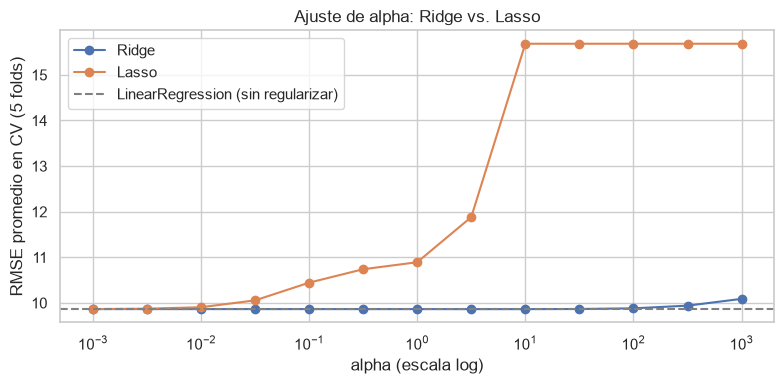

Mejor modelo regularizado según RMSE en CV: Ridge {'modelo__alpha': np.float64(3.1622776601683795)}


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for nombre in curvas:
    ax.plot(curvas.index, curvas[nombre], marker="o", label=nombre)
ax.axhline(rmse_cv_lineal.mean(), color="gray", ls="--", label="LinearRegression (sin regularizar)")
ax.set(xscale="log", xlabel="alpha (escala log)", ylabel="RMSE promedio en CV (5 folds)",
       title="Ajuste de alpha: Ridge vs. Lasso")
ax.legend()
plt.tight_layout()
config.FIGURAS.mkdir(parents=True, exist_ok=True)
plt.savefig(config.FIGURAS / "03_ajuste_alpha.png", dpi=120)
plt.show()

mejor = min(resultados, key=lambda n: -resultados[n].best_score_)
print("Mejor modelo regularizado según RMSE en CV:", mejor, resultados[mejor].best_params_)

**Lectura:**
- **Ridge** queda prácticamente plano hasta `alpha ≈ 30` y gana por muy poco con `alpha ≈ 3.16`; con más penalización el error sube porque el modelo se simplifica de más.
- **Lasso** es mejor con el `alpha` más chico de la grilla (0.001) y empeora rápido al subirlo: a partir de `alpha = 10` anula todos los coeficientes y queda igual a predecir siempre el promedio.
- Ambos quedan casi empatados con la regresión lineal sin regularizar. **¿Por qué la regularización casi no ayuda?** Porque hay ~88 000 filas para estimar 129 coeficientes: con tantos datos por coeficiente, la regresión lineal ya no sobreajusta (lo confirma Train ≈ Test en la sección 3), y la regularización tiene poco que corregir. El límite de este modelo no es la varianza, es el **sesgo**: la relación con el flete no es lineal.
- **Se elige Ridge** por tener el menor RMSE en CV. Además, sus coeficientes son más estables frente a la correlación entre peso y medidas, lo que ayuda a interpretarlos.

### 2.1 Variante con logaritmo (alternativa descartada)

Hipótesis: `peso_g`, `volumen_cm3` y `precio` son muy asimétricas (pocos productos enormes o caros). Aplicarles `log1p` antes del escalado podría acercar su relación con el flete a una recta. Se prueba con Ridge y la misma grilla, y se decide **por RMSE en CV**, no por Test.

El log va como primer paso del Pipeline (`FunctionTransformer`): se calcula fila por fila, así que no introduce fuga.

In [6]:
COLUMNAS_LOG = ["peso_g", "volumen_cm3", "precio"]

def aplicar_log(X):
    X = X.copy()
    X[COLUMNAS_LOG] = np.log1p(X[COLUMNAS_LOG])
    return X

pipe_log = Pipeline([("log", FunctionTransformer(aplicar_log)),
                     ("prep", crear_preprocesador_lineal()),
                     ("modelo", Ridge())])
grid_log = GridSearchCV(pipe_log, {"modelo__alpha": ALPHAS}, cv=config.CV_FOLDS,
                        scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_log.fit(X_train, y_train)

pd.DataFrame({
    "variante": ["Ridge (variables originales)", "Ridge (log en peso/volumen/precio)"],
    "mejor_alpha": [resultados["Ridge"].best_params_["modelo__alpha"], grid_log.best_params_["modelo__alpha"]],
    "RMSE_CV": [-resultados["Ridge"].best_score_, -grid_log.best_score_],
}).round(4)

,variante,mejor_alpha,RMSE_CV
0,Ridge (variables originales),3.1623,9.8639
1,Ridge (log en peso/volumen/precio),3.1623,11.3640


In [7]:
# Solo como referencia para documentar la decisión (no se usó para elegir):
print("Ridge original · Test:", {k: round(v, 3) for k, v in calcular_metricas(y_test, resultados["Ridge"].predict(X_test)).items()})
print("Ridge con log  · Test:", {k: round(v, 3) for k, v in calcular_metricas(y_test, grid_log.predict(X_test)).items()})

Ridge original · Test: {'RMSE': 9.601, 'MAE': 5.004, 'R2': 0.628}
Ridge con log  · Test: {'RMSE': 11.306, 'MAE': 6.041, 'R2': 0.484}


**Decisión: se descarta el log.** Empeora el RMSE en CV (≈9.86 → ≈11.36) y el R² en Test baja de ≈0.63 a ≈0.48.

**¿Por qué empeora?** El log *comprime* los valores grandes: la diferencia entre 10 kg y 30 kg queda casi igual a la que hay entre 100 g y 300 g. Pero el flete **sí crece fuerte** con los productos grandes y pesados (cobro por peso volumétrico), así que al comprimirlos el modelo pierde justamente la señal que explica los fletes altos, que son los que más pesan en el RMSE. Una alternativa que quedaría por probar sería aplicar el log al **target**, pero entonces las métricas dejarían de estar en reales y habría que transformarlas de vuelta; queda fuera del alcance.

## 3. Registro de métricas

Se registran en `reports/metricas_modelos.csv` (tabla común del notebook 05) la **línea base lineal** y el **mejor regularizado (Ridge)**. Se calculan en Train y en Test para detectar sobreajuste.

In [8]:
tabla_lineal = registrar_metricas("RegresionLineal", "Fabio", lineal, X_train, y_train, X_test, y_test)
tabla_mejor = registrar_metricas(mejor, "Fabio", resultados[mejor].best_estimator_,
                                 X_train, y_train, X_test, y_test,
                                 {k: float(v) for k, v in resultados[mejor].best_params_.items()})
pd.concat([tabla_lineal, tabla_mejor], ignore_index=True)

,modelo,responsable,RMSE_train,MAE_train,R2_train,RMSE_test,MAE_test,R2_test,mejores_parametros
0,RegresionLineal,Fabio,9.837,5.106,0.607,9.602,5.005,0.628,{}
1,Ridge,Fabio,9.837,5.105,0.607,9.601,5.004,0.628,{'modelo__alpha': 3.1622776601683795}


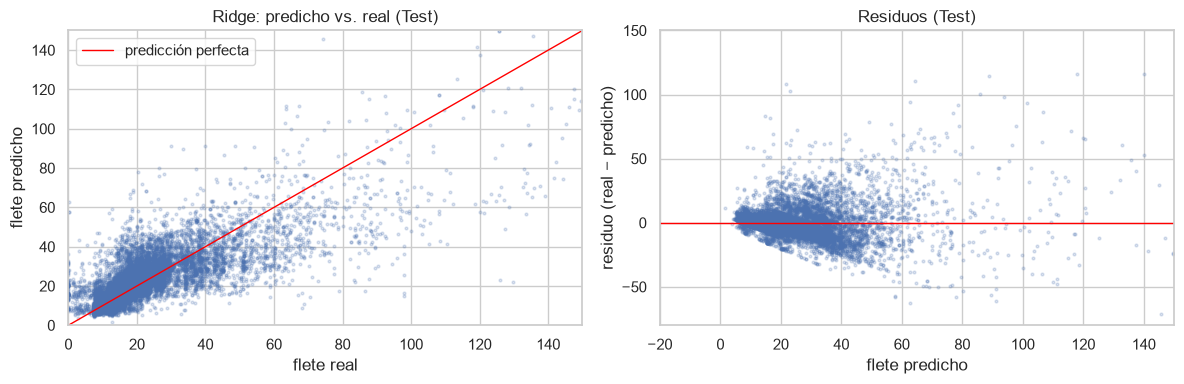

Predicciones negativas en Test: 0 de 22040


In [9]:
# Predicción vs. real y residuos en Test (mejor modelo)
modelo_final = resultados[mejor].best_estimator_
pred = modelo_final.predict(X_test)
residuos = y_test - pred

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].scatter(y_test, pred, s=4, alpha=0.2)
lim = [0, 150]
ejes[0].plot(lim, lim, color="red", lw=1, label="predicción perfecta")
ejes[0].set(xlim=lim, ylim=lim, xlabel="flete real", ylabel="flete predicho", title=f"{mejor}: predicho vs. real (Test)")
ejes[0].legend()
ejes[1].scatter(pred, residuos, s=4, alpha=0.2)
ejes[1].axhline(0, color="red", lw=1)
ejes[1].set(xlim=[-20, 150], ylim=[-80, 150], xlabel="flete predicho", ylabel="residuo (real − predicho)",
            title="Residuos (Test)")
plt.tight_layout()
plt.savefig(config.FIGURAS / "03_predicho_vs_real.png", dpi=120)
plt.show()

print(f"Predicciones negativas en Test: {(pred < 0).sum()} de {len(pred)}")

**Lectura:**
- **No hay sobreajuste:** las métricas de Train y Test son muy parecidas (R² ≈ 0.61 en Train y ≈ 0.63 en Test; RMSE ≈ 9.8 vs ≈ 9.6). Si el modelo memorizara Train, el error en Test sería claramente mayor.
- RMSE (≈9.6) es casi el doble del MAE (≈5.0): hay **errores grandes en pocos ítems**, que el RMSE castiga más.
- En el gráfico, los fletes altos quedan **por debajo de la diagonal** (el modelo los subestima) y los residuos se abren en abanico al crecer la predicción. Es el síntoma típico de una relación no lineal que una recta no puede seguir.

## 4. Coeficientes más importantes

Los coeficientes de las **numéricas** están en escala estandarizada, así que se leen como *"si la variable sube 1 desviación estándar, manteniendo el resto igual, el flete cambia en X reales"*. Los de las **categóricas One-Hot** se leen como *"pertenecer a esta categoría suma/resta X reales"* frente al promedio de las demás. Por eso conviene mirarlos por separado.

In [10]:
est = resultados[mejor].best_estimator_
nombres = est.named_steps["prep"].get_feature_names_out()
coef = pd.Series(est.named_steps["modelo"].coef_, index=nombres)

print("Top 10 coeficientes en valor absoluto (todas las columnas):")
top10 = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
conteos = {f"cat__{c}_{v}": n for c in config.VARIABLES_CATEGORICAS for v, n in X_train[c].value_counts().items()}
pd.DataFrame({"coeficiente": top10.round(2), "filas_en_train": [conteos.get(i, len(X_train)) for i in top10.index]})

Top 10 coeficientes en valor absoluto (todas las columnas):


,coeficiente,filas_en_train
cat__estado_vendedor_RO,18.36,12
cat__estado_cliente_RR,11.59,35
cat__estado_cliente_PB,10.67,457
cat__estado_cliente_SP,-9.89,37090
cat__estado_cliente_RO,9.48,215
cat__categoria_producto_furniture_mattress_and_upholstery,9.39,28
cat__estado_cliente_RJ,-9.11,11387
cat__estado_cliente_AC,8.92,72
cat__estado_cliente_PR,-8.89,4531
cat__estado_cliente_MG,-8.87,10329


In [11]:
num = coef[[f"num__{c}" for c in config.VARIABLES_NUMERICAS]]
num.index = config.VARIABLES_NUMERICAS
desv = X_train[config.VARIABLES_NUMERICAS].std()
tabla_num = pd.DataFrame({"coeficiente (por 1 desv.)": num.round(2), "1 desviación equivale a": desv.round(2)})
display(tabla_num.reindex(num.abs().sort_values(ascending=False).index))

for var in ["volumen_cm3", "peso_g", "precio"]:
    print(f"+1 desviación de {var} (≈ {desv[var]:,.0f}) → {num[var]:+.2f} en flete")
print(f"Mismo estado (de 0 a 1) → {num['mismo_estado'] / desv['mismo_estado']:+.2f} en flete")

,coeficiente (por 1 desv.),1 desviación equivale a
volumen_cm3,6.97,23241.20
peso_g,5.20,3743.80
mismo_estado,-3.06,0.48
precio,2.80,180.69
alto_cm,-2.07,13.46
ancho_cm,-1.49,11.67
largo_cm,-0.61,16.13
numero_item,-0.15,0.70


+1 desviación de volumen_cm3 (≈ 23,241) → +6.97 en flete
+1 desviación de peso_g (≈ 3,744) → +5.20 en flete
+1 desviación de precio (≈ 181) → +2.80 en flete
Mismo estado (de 0 a 1) → -6.37 en flete


In [12]:
lasso = resultados["Lasso"].best_estimator_.named_steps["modelo"]
print(f"Lasso (alpha={resultados['Lasso'].best_params_['modelo__alpha']}) anuló {(lasso.coef_ == 0).sum()} de {len(lasso.coef_)} coeficientes:")
print(sorted(pd.Series(lasso.coef_, index=nombres)[lambda s: s == 0].index.str.replace("cat__", "")))

Lasso (alpha=0.001) anuló 32 de 129 coeficientes:
['categoria_producto_arts_and_craftmanship', 'categoria_producto_books_general_interest', 'categoria_producto_books_imported', 'categoria_producto_cds_dvds_musicals', 'categoria_producto_cine_photo', 'categoria_producto_construction_tools_safety', 'categoria_producto_costruction_tools_tools', 'categoria_producto_dvds_blu_ray', 'categoria_producto_electronics', 'categoria_producto_fashio_female_clothing', 'categoria_producto_fashion_childrens_clothes', 'categoria_producto_fashion_male_clothing', 'categoria_producto_fashion_sport', 'categoria_producto_fashion_underwear_beach', 'categoria_producto_flowers', 'categoria_producto_food', 'categoria_producto_food_drink', 'categoria_producto_industry_commerce_and_business', 'categoria_producto_la_cuisine', 'categoria_producto_music', 'categoria_producto_party_supplies', 'categoria_producto_security_and_services', 'categoria_producto_small_appliances_home_oven_and_coffee', 'categoria_producto_spo

**Interpretación:**
- **Numéricas (tamaño, peso y distancia):** `volumen_cm3` (+≈7.0 por desviación, unos 23 000 cm³) y `peso_g` (+≈5.2 por desviación, unos 3.7 kg) son las de mayor efecto positivo; luego `precio` (+≈2.8). Que el cliente y el vendedor estén en el **mismo estado baja el flete ≈6.4 reales** por ítem. Es la misma historia que contó el Random Forest: **el envío se cobra por tamaño, peso y distancia**.
- **Signos negativos de `alto_cm`, `ancho_cm`, `largo_cm`:** no significan que una caja más alta sea más barata. Las medidas están muy correlacionadas con `volumen_cm3` y `peso_g` (hasta 0.8), así que el modelo reparte el efecto entre ellas y los signos individuales dejan de tener lectura propia. Lo interpretable es el efecto conjunto del tamaño.
- **Top 10 global dominado por estados:** los estados lejanos del norte (`RR`, `AC`, `RO`, `PB` como destino) suman entre 9 y 12 reales y los del sureste (`SP`, `RJ`, `MG`, `PR`) restan 8–10 reales. Es la distancia otra vez, con más detalle que `mismo_estado`. **Ojo:** el coeficiente más alto, `estado_vendedor_RO` (+≈18), se apoya en solo 12 filas de Train, así que es poco confiable; no conviene presentarlo como hallazgo. Lo mismo pasa con `furniture_mattress_and_upholstery` (28 filas).
- **Lasso** anula 32 de 129 columnas: 24 categorías de producto (por ejemplo libros, ropa, electrónica), 7 estados de vendedor y 1 estado de cliente. Son categorías cuyo flete no se distingue del promedio una vez que el modelo ya conoce peso, volumen y destino, así que no aportan información adicional.

## Conclusiones

1. **Modelo 1 elegido: Ridge con `alpha ≈ 3.16`**, seleccionado por RMSE en validación cruzada de 5 folds sobre Train. En Test: **RMSE ≈ 9.60, MAE ≈ 5.00, R² ≈ 0.63**.
2. Frente a cotizar con la mediana, el error promedio baja de ≈7.7 a ≈5.0 reales por ítem (≈35 % menos).
3. **La regularización casi no cambia el resultado** respecto a la regresión lineal: con ~88 000 filas para 129 coeficientes no hay sobreajuste (Train ≈ Test). El problema del modelo lineal es de **sesgo**, no de varianza.
4. **Alternativa descartada:** log en peso/volumen/precio. Empeora el RMSE en CV (≈11.4 vs ≈9.9) y el R² en Test (≈0.48 vs ≈0.63) porque comprime justamente los productos grandes, que son los que encarecen el envío.
5. **Interpretación:** volumen, peso y distancia (estado de destino y `mismo_estado`) son lo que más mueve el flete, coherente con cómo cobran las transportistas.
6. **Límite del modelo lineal:** supone efectos aditivos y en línea recta. El flete tiene **saltos por tramos de peso e interacciones** (un producto pesado enviado lejos cuesta más que la suma de "pesado" + "lejos"), que el modelo no puede representar; por eso subestima los fletes altos. Los modelos de árboles del notebook 04 capturan esas interacciones y deberían rendir mejor (en la prueba rápida, Random Forest R² ≈ 0.75).